# 3. Measure and compare performance (shortlist promising models)

**Owner:** Joel Tomy

This notebook covers the *Shortlist Promising Models* part of Géron's checklist (Appendix B) and the "Measure and Compare Performance" half of the rubric's third row:

| Checklist item | Where |
|---|---|
| Train many quick-and-dirty models from different categories with standard parameters | §3.3 |
| N-fold cross-validation, mean and standard deviation of the performance measure | §3.3, §3.6 |
| Analyze the most significant variables for each algorithm | §3.4, §3.7 |
| Analyze the types of errors the models make | §3.5 |
| What data would a human have used to avoid these errors? | §3.5 |
| Quick round of feature selection and engineering | §3.6 |
| One or two more quick iterations | §3.6, §3.7 |
| Shortlist the top three to five models, preferring models that make different types of errors | §3.8 |

**Leak-free protocol.** We use Notebook 02's claim-grouped split and its feature engineering and preprocessing pipeline (`src/preprocessing.py`), placed *inside* each model's scikit-learn `Pipeline` so imputation, outlier clipping, log transforms, Age bins, scaling, one-hot encoding and TF-IDF are re-fitted on the training folds of every CV split. The 15% test split from Notebook 02 is never loaded here; it is used exactly once, at the end of Notebook 04.

In [1]:
import sys
import time
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVR
from sklearn.tree import DecisionTreeRegressor
import lightgbm as lgb
import xgboost as xgb

REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.modeling import (
    INITIAL_COL, TEXT_COL, ID_COL, TARGET_COL, RANDOM_STATE, SENSITIVE_COLS,
    load_splits, make_xy, group_folds, build_feature_pipeline, feature_names, regression_report,
)

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")

FIGURES_DIR = REPO_ROOT / "reports" / "figures"
TABLES_DIR = REPO_ROOT / "reports" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

N_JOBS = -1  # use every CPU core for the cross-validation folds

## 3.1 Data, target and evaluation design

**What we predict.** The model predicts `UltimateIncurredClaimCost` from information available at first notice of loss (FNOL), including the adjuster's own `InitialIncurredCalimsCost`. Predicting the ultimate cost is equivalent to predicting the reserve shortfall from the EDA notebook: `predicted shortfall = predicted ultimate − initial reserve`, because the initial reserve is a known input. We model the dollar amount because the business question ("how far off is the reserve, in dollars?") and the README's baseline comparison are both in dollars.

**Metrics** (from the README framing, all in dollars):
* **MAE** (primary): average dollar distance between prediction and final cost, directly comparable with the adjuster's reserve error.
* **RMSE** (secondary): penalises large misses more, which matters because a single badly under-reserved claim is expensive.
* **Median AE**: the error on a *typical* claim (MAE and RMSE are dominated by a few very large claims).
* **Mean bias (actual − predicted)**: positive means the model under-reserves on average, which matters for aggregate reserve adequacy.

**Validation design.**
* We re-create Notebook 02's exact claim-grouped 70 / 15 / 15 split (`GroupShuffleSplit` on `ClaimNumber`, `random_state=42`); the next cell verifies it row by row against `data/processed/train.parquet`.
* Model comparison uses **5-fold cross-validation on the 70% train split only**, with `GroupKFold` on `ClaimNumber` so the folds follow the same rule as Notebook 02's split: rows sharing a claim number never sit on both sides.
* The 15% validation split is used for permutation importance (§3.4), so importance is measured on data the models were not trained on.
* The 15% test split stays locked until Notebook 04.

In [2]:
train_df, val_df, test_df = load_splits(REPO_ROOT)
X_train, y_train = make_xy(train_df)
X_val, y_val = make_xy(val_df)

# Same rows, same order as Notebook 02's exported split
nb02_train = pd.read_parquet(REPO_ROOT / "data" / "processed" / "train.parquet")
assert len(nb02_train) == len(train_df)
assert np.allclose(nb02_train["raw_UltimateIncurredClaimCost"].values, y_train.values)
print("Split matches data/processed/train.parquet row for row.")

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test (locked): {test_df.shape}")
print("Model input columns (Notebook 02 feature engineering):", X_train.columns.tolist())

Split matches data/processed/train.parquet row for row.
Train: (25339, 37) | Val: (5406, 37) | Test (locked): (5431, 17)
Model input columns (Notebook 02 feature engineering): ['Age', 'Gender', 'MaritalStatus', 'DependentChildren', 'DependentsOther', 'WeeklyWages', 'PartTimeFullTime', 'HoursWorkedPerWeek', 'DaysWorkedPerWeek', 'ClaimDescription', 'InitialIncurredCalimsCost', 'negative_lag_flag', 'lag_over_1yr_flag', 'ReportingLagDays', 'AccidentYear', 'MedicalCPI', 'CPI_Multiplier_to_2005', 'InitialCost_Real2005', 'WeeklyWages_Real2005', 'DateTimeOfAccident_year', 'DateTimeOfAccident_month', 'DateTimeOfAccident_day', 'DateTimeOfAccident_dayofweek', 'DateTimeOfAccident_hour', 'DateTimeOfAccident_is_weekend', 'DateReported_year', 'DateReported_month', 'DateReported_day', 'DateReported_dayofweek', 'DateReported_hour', 'DateReported_is_weekend', 'invalid_hours_flag', 'age_under_14_flag', 'ApproxHourlyWage', 'HoursPerDay', 'TotalDependents', 'InitialReserveToWageRatio']


**Do repeated `ClaimNumber`s mean the same claim appears in several rows?** The EDA flagged repeated IDs, and Notebook 02 groups its split by `ClaimNumber` to be safe. The check below shows that rows sharing an ID have different accident dates, descriptions and costs, so they look like distinct claims with recycled IDs. Grouping is therefore a conservative choice rather than a strict necessity, but we keep it in our CV folds so the whole project follows one rule.

In [3]:
dup = train_df[train_df[ID_COL].duplicated(keep=False)]
same_claim_check = dup.groupby(ID_COL).agg(
    rows=("DateTimeOfAccident", "size"),
    distinct_accident_dates=("DateTimeOfAccident", "nunique"),
    distinct_descriptions=(TEXT_COL, "nunique"),
)
share_distinct = (same_claim_check["distinct_accident_dates"] == same_claim_check["rows"]).mean()
print(f"Train rows with a repeated ClaimNumber: {len(dup):,}")
print(f"Share of repeated IDs whose rows all have different accident dates: {share_distinct:.1%}")
display(same_claim_check.head())

Train rows with a repeated ClaimNumber: 8,836
Share of repeated IDs whose rows all have different accident dates: 100.0%


,rows,distinct_accident_dates,distinct_descriptions
ClaimNumber,,,
WC1601116,2,2,2
WC1602516,3,3,3
WC1603416,2,2,2
WC1609916,2,2,2
WC1612316,2,2,2


## 3.2 Baselines: what does "good" look like?

A model is only useful if it beats what the business already does. We evaluate three baselines with the same 5 folds:

1. **Predict the mean** (`DummyRegressor(strategy="mean")`): the floor any model must clear.
2. **Predict the median** (`DummyRegressor(strategy="median")`): the constant that minimises MAE.
3. **Adjuster's initial reserve** (the current process): predict `UltimateIncurredClaimCost = InitialIncurredCalimsCost`. This is the benchmark named in the README.
4. **Initial reserve × development factor**: a simple actuarial adjustment that multiplies the reserve by the median `ultimate / initial` ratio learned on the training folds. It tests whether a one-number correction is already enough.

In [4]:
FOLDS = group_folds(X_train, train_df[ID_COL])
fold_overlap = max(len(set(train_df[ID_COL].iloc[tr]) & set(train_df[ID_COL].iloc[va])) for tr, va in FOLDS)
print(f"Claim numbers shared between a training fold and its validation fold: {fold_overlap}")


def _fit_fold(pipe, X, y, tr_idx, va_idx):
    model = clone(pipe)
    t0 = time.time()
    model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    fit_s = time.time() - t0
    return va_idx, model.predict(X.iloc[va_idx]), fit_s


def cv_evaluate(pipe, X=X_train, y=y_train, folds=FOLDS):
    # Fit `pipe` on each training fold, predict the held-out fold.
    # Returns (per-fold metric table, out-of-fold predictions for every training row).
    results = Parallel(n_jobs=N_JOBS)(
        delayed(_fit_fold)(pipe, X, y, tr, va) for tr, va in folds
    )
    oof = np.zeros(len(y))
    rows = []
    for va_idx, pred, fit_s in results:
        oof[va_idx] = pred
        rows.append({**regression_report(y.iloc[va_idx], pred), "fit_seconds": fit_s})
    return pd.DataFrame(rows), oof


def summarise(name, fold_df, family, iteration):
    # Mean and standard deviation over the N folds, as the checklist asks.
    out = {"model": name, "family": family, "iteration": iteration}
    for m in ["MAE", "RMSE", "MedianAE", "MeanBias(actual-pred)"]:
        out[f"{m}_mean"] = fold_df[m].mean()
        out[f"{m}_std"] = fold_df[m].std()
    out["fit_seconds"] = fold_df["fit_seconds"].mean()
    return out


summary_rows, OOF = [], {}

# Baselines 1-2: dummy regressors (structured columns only; they ignore X anyway)
for strat in ["mean", "median"]:
    pipe = Pipeline([("model", DummyRegressor(strategy=strat))])
    folds_df, OOF[f"Dummy ({strat})"] = cv_evaluate(pipe, X_train.drop(columns=[TEXT_COL]))
    summary_rows.append(summarise(f"Dummy ({strat})", folds_df, "Baseline", "0 - baselines"))

# Baseline 3: the adjuster's initial reserve (no training needed)
rows, oof = [], np.zeros(len(y_train))
for tr, va in FOLDS:
    pred = X_train[INITIAL_COL].iloc[va].values
    oof[va] = pred
    rows.append({**regression_report(y_train.iloc[va], pred), "fit_seconds": 0.0})
OOF["Adjuster initial reserve"] = oof
summary_rows.append(summarise("Adjuster initial reserve", pd.DataFrame(rows), "Baseline", "0 - baselines"))

# Baseline 4: initial reserve x median development factor learned on the training folds
rows, oof = [], np.zeros(len(y_train))
for tr, va in FOLDS:
    factor = np.median(y_train.iloc[tr] / X_train[INITIAL_COL].iloc[tr])
    pred = X_train[INITIAL_COL].iloc[va].values * factor
    oof[va] = pred
    rows.append({**regression_report(y_train.iloc[va], pred), "fit_seconds": 0.0})
OOF["Initial x dev. factor"] = oof
summary_rows.append(summarise("Initial x dev. factor", pd.DataFrame(rows), "Baseline", "0 - baselines"))

baseline_table = pd.DataFrame(summary_rows).set_index("model")
display(baseline_table[["MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std", "MedianAE_mean", "MeanBias(actual-pred)_mean"]])

Claim numbers shared between a training fold and its validation fold: 0


,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MedianAE_mean,MeanBias(actual-pred)_mean
model,,,,,,
Dummy (mean),"12,348.65",437.68,"27,445.83","3,099.54","8,998.09",1.00
Dummy (median),"9,588.35",490.33,"28,425.03","3,108.21","2,792.93","7,407.32"
Adjuster initial reserve,"6,161.06",315.95,"24,581.05","2,181.16","1,036.13","2,995.12"
Initial x dev. factor,"6,308.77",301.78,"24,808.96","2,122.95","1,068.33","2,489.43"


**Takeaways from the baselines**
* The adjuster's initial reserve is a strong benchmark: **MAE $6,161 ± 316**, far better than predicting a constant (median: $9,588; mean: $12,349). Any model must beat **$6,161** to be useful.
* The adjuster is biased low: on average the final cost is **$2,995 higher** than the reserve (under-reserving on 54% of claims).
* Multiplying the reserve by a single development factor *hurts* MAE ($6,309): it shrinks the average bias but moves already-accurate small reserves away from their true value. A one-number correction is not enough, which justifies a claim-level model.
* RMSE has a large fold-to-fold standard deviation (≈ $2,000–3,000) for every method because a few claims above $400,000 land in different folds. This is why MAE, not RMSE, is our primary comparison metric.

## 3.3 Iteration 1: quick-and-dirty models from many families (structured features only)

Following the checklist, we train one model from each major family with close-to-default hyperparameters:

| Family | Model | Why it is in the race |
|---|---|---|
| Linear | `Ridge` | Fast, interpretable coefficients, a strong baseline once features are log-transformed and scaled |
| Support vector machine | `LinearSVR` | Epsilon-insensitive loss behaves like an absolute-error loss, which matches our MAE metric. (A kernel SVR is O(n²) and too slow for 25k rows.) |
| Instance-based | `KNeighborsRegressor` | Non-parametric: "similar claims cost similar amounts" |
| Single tree | `DecisionTreeRegressor` | Captures thresholds and interactions; reference point for the ensembles |
| Bagging | `RandomForestRegressor` | Averages many decorrelated trees, robust to outliers in inputs |
| Boosting | `LGBMRegressor`, `XGBRegressor` | State of the art on tabular data |
| Neural network | `MLPRegressor` | Smooth non-linear function of all features |

Naive Bayes is listed in the checklist but is a classifier, so it does not apply to this regression problem.

**Target transform.** Every model is wrapped in `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`: it learns `log(1 + cost)` and converts predictions back to dollars. Claim costs range from under $100 to over $4M (EDA §1.5); on the raw scale the squared-error loss would be driven by a handful of huge claims. §3.7 checks this choice empirically against other losses.

In this first iteration models see only the **structured** columns (no claim description) so we can measure what the free text adds later.

In [5]:
LINEAR_MODELS = {"Ridge", "LinearSVR"}

MODEL_ZOO = {
    "Ridge": ("Linear", lambda: Ridge(alpha=1.0)),
    "LinearSVR": ("SVM", lambda: LinearSVR(epsilon=0.0, C=0.1, max_iter=5000, random_state=RANDOM_STATE)),
    "KNN": ("Instance-based", lambda: KNeighborsRegressor(n_neighbors=15, weights="distance")),
    "DecisionTree": ("Single tree", lambda: DecisionTreeRegressor(min_samples_leaf=50, random_state=RANDOM_STATE)),
    "RandomForest": ("Bagging", lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.3,
                                                              n_jobs=1, random_state=RANDOM_STATE)),
    "LightGBM": ("Boosting", lambda: lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, n_jobs=1,
                                                       random_state=RANDOM_STATE, verbose=-1)),
    "XGBoost": ("Boosting", lambda: xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, n_jobs=1,
                                                     random_state=RANDOM_STATE)),
    "MLP": ("Neural net", lambda: MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                               max_iter=300, random_state=RANDOM_STATE)),
}


def make_pipeline(name, X, use_text, **feature_kwargs):
    # Linear models get the sparse TF-IDF matrix (one weight per word); every other
    # family gets 50 dense SVD 'topics' because trees/KNN/MLP struggle with 2,000 sparse columns.
    svd = None if name in LINEAR_MODELS else 50
    feature_kwargs.setdefault("text_svd_components", svd)
    return Pipeline([
        ("features", build_feature_pipeline(X, use_text=use_text, **feature_kwargs)),
        ("model", TransformedTargetRegressor(regressor=MODEL_ZOO[name][1](), func=np.log1p, inverse_func=np.expm1)),
    ])


X_train_struct = X_train.drop(columns=[TEXT_COL])
for name, (family, _) in MODEL_ZOO.items():
    t0 = time.time()
    folds_df, OOF[f"{name} | it1"] = cv_evaluate(make_pipeline(name, X_train_struct, use_text=False), X_train_struct)
    summary_rows.append(summarise(name, folds_df, family, "1 - structured"))
    print(f"{name:<13} MAE {folds_df['MAE'].mean():>8,.0f} ± {folds_df['MAE'].std():>5,.0f}   ({time.time() - t0:,.0f}s)")

Ridge         MAE    5,916 ±   379   (1s)


LinearSVR     MAE    5,745 ±   413   (3s)


KNN           MAE    6,562 ±   452   (2s)


DecisionTree  MAE    5,915 ±   425   (1s)


RandomForest  MAE    5,722 ±   397   (14s)


LightGBM      MAE    5,757 ±   398   (5s)


XGBoost       MAE    5,818 ±   369   (7s)


MLP           MAE    6,093 ±   288   (11s)


,model,family,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MedianAE_mean,MeanBias(actual-pred)_mean,MAE_vs_adjuster_%,fit_seconds
0,RandomForest,Bagging,"5,722.23",397.15,"23,045.38","3,049.44",933.90,"3,076.85",-7.12,4.64
1,LinearSVR,SVM,"5,745.43",412.53,"23,507.59","3,049.41",861.69,"4,133.52",-6.75,0.99
2,LightGBM,Boosting,"5,757.35",398.33,"22,964.36","3,041.78",938.48,"2,905.48",-6.55,1.38
3,XGBoost,Boosting,"5,818.04",369.01,"22,985.43","2,917.59",930.34,"2,791.64",-5.57,2.18
4,DecisionTree,Single tree,"5,915.14",425.35,"23,085.28","3,039.68",998.31,"2,894.70",-3.99,0.42
5,Ridge,Linear,"5,916.11",378.68,"23,045.90","2,977.75",997.51,"3,017.84",-3.98,0.31
6,MLP,Neural net,"6,092.72",288.39,"23,321.86","3,026.17","1,005.93","2,807.34",-1.11,3.43
7,Adjuster initial reserve,Baseline,"6,161.06",315.95,"24,581.05","2,181.16","1,036.13","2,995.12",0.00,0.00
8,Initial x dev. factor,Baseline,"6,308.77",301.78,"24,808.96","2,122.95","1,068.33","2,489.43",2.40,0.00
9,KNN,Instance-based,"6,561.91",452.30,"25,102.90","3,173.78","1,065.65","5,159.29",6.51,0.28


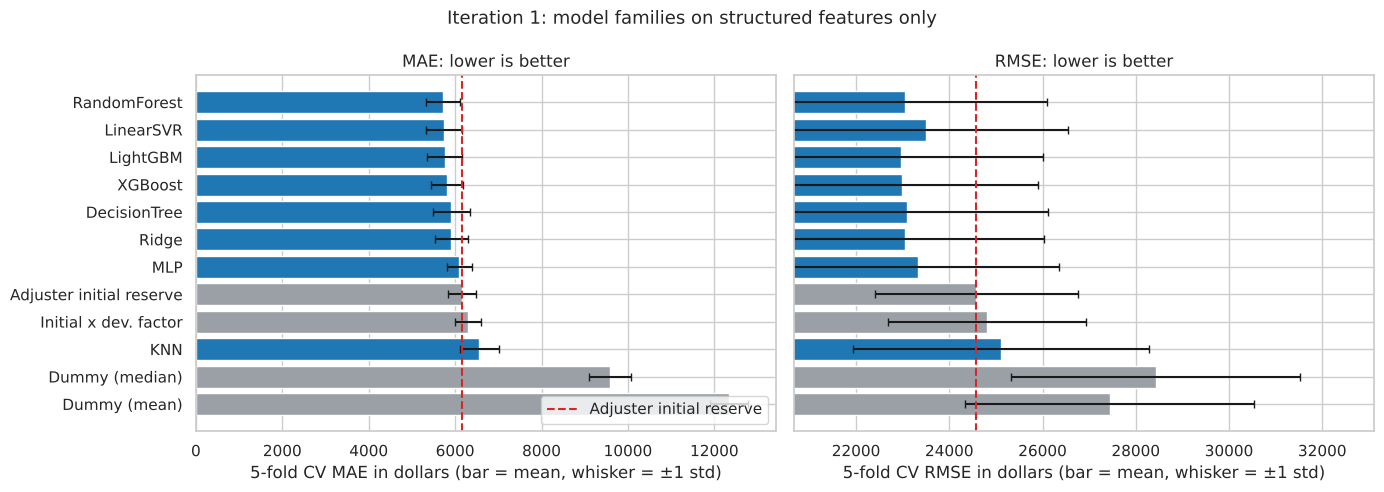

In [6]:
def results_table(iteration):
    t = pd.DataFrame(summary_rows)
    t = t[t["iteration"].isin(["0 - baselines", iteration])].copy()
    adj = t.loc[t["model"] == "Adjuster initial reserve", "MAE_mean"].iloc[0]
    t["MAE_vs_adjuster_%"] = 100 * (t["MAE_mean"] / adj - 1)
    cols = ["model", "family", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std", "MedianAE_mean",
            "MeanBias(actual-pred)_mean", "MAE_vs_adjuster_%", "fit_seconds"]
    return t[cols].sort_values("MAE_mean").reset_index(drop=True)


def plot_cv(table, title, fname):
    t = table.sort_values("MAE_mean", ascending=True)
    colors = ["#9aa0a6" if f == "Baseline" else "#1f77b4" for f in t["family"]]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, m in zip(axes, ["MAE", "RMSE"]):
        ax.barh(t["model"], t[f"{m}_mean"], xerr=t[f"{m}_std"], color=colors, capsize=3)
        adj = t.loc[t["model"] == "Adjuster initial reserve", f"{m}_mean"].iloc[0]
        ax.axvline(adj, color="#d62728", ls="--", label="Adjuster initial reserve")
        ax.set_xlabel(f"5-fold CV {m} in dollars (bar = mean, whisker = ±1 std)")
        ax.set_title(f"{m}: lower is better")
        if m == "RMSE":
            ax.set_xlim(left=t["RMSE_mean"].min() * 0.9)
    axes[0].invert_yaxis()
    axes[0].legend(loc="lower right")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


it1_table = results_table("1 - structured")
display(it1_table)
plot_cv(it1_table, "Iteration 1: model families on structured features only", "03_cv_iteration1_structured.png")

**Iteration 1 results (structured features only)**
* Seven of eight model families beat the adjuster on MAE. The best are **RandomForest ($5,722, −7.1%)**, **LinearSVR ($5,745, −6.8%)** and **LightGBM ($5,757, −6.6%)**.
* **KNN is worse than the adjuster ($6,562)**: with ~35 scaled dimensions, "nearest neighbours" are not similar claims (curse of dimensionality), and distance weighting cannot learn that the initial reserve matters far more than, say, the day of the month.
* Differences between the top three models (≈ $35) are much smaller than the fold standard deviation (≈ $400), so at this stage no single family is clearly best. This is why we keep several families and look at *how* they err, not just their average score.
* Every model still has a positive mean bias (≈ $2,800–4,100): all of them under-predict the dollar total. §3.7 explains why.

## 3.4 Most significant variables for each algorithm

Each algorithm has its own native notion of importance (coefficients, split gain, none at all for KNN), which makes cross-model comparison hard. We therefore use one **model-agnostic** measure for all of them: **permutation importance on the validation split**. Each model is fitted on the full training split; then one *raw input column* at a time is shuffled in the validation data and we record how much MAE gets worse. A large increase means the model relies on that column. Because shuffling acts on raw columns before the pipeline, engineered pieces (e.g. the log-transformed reserve) are credited back to the column they come from.

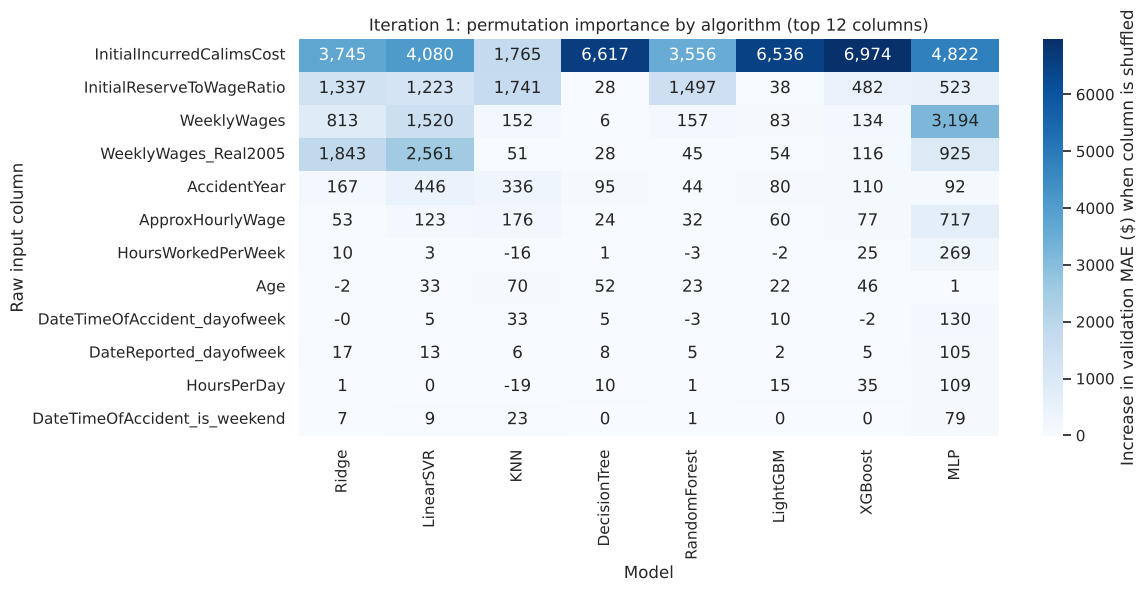

In [7]:
def fit_on_train(name, X, use_text, **kw):
    return make_pipeline(name, X, use_text, **kw).fit(X, y_train)


def mae_scorer(est, X, y):
    return -np.mean(np.abs(np.asarray(y) - est.predict(X)))


X_val_struct = X_val.drop(columns=[TEXT_COL])
fitted_it1, perm_it1 = {}, {}
for name in MODEL_ZOO:
    fitted_it1[name] = fit_on_train(name, X_train_struct, use_text=False)
    r = permutation_importance(fitted_it1[name], X_val_struct, y_val, scoring=mae_scorer,
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    perm_it1[name] = pd.Series(r.importances_mean, index=X_val_struct.columns)

perm_it1 = pd.DataFrame(perm_it1)
top_cols = perm_it1.mean(axis=1).sort_values(ascending=False).head(12).index
plt.figure(figsize=(12, 6))
sns.heatmap(perm_it1.loc[top_cols], annot=True, fmt=",.0f", cmap="Blues",
            cbar_kws={"label": "Increase in validation MAE ($) when column is shuffled"})
plt.title("Iteration 1: permutation importance by algorithm (top 12 columns)")
plt.xlabel("Model")
plt.ylabel("Raw input column")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_permutation_importance_iteration1.png", dpi=150, bbox_inches="tight")
plt.show()

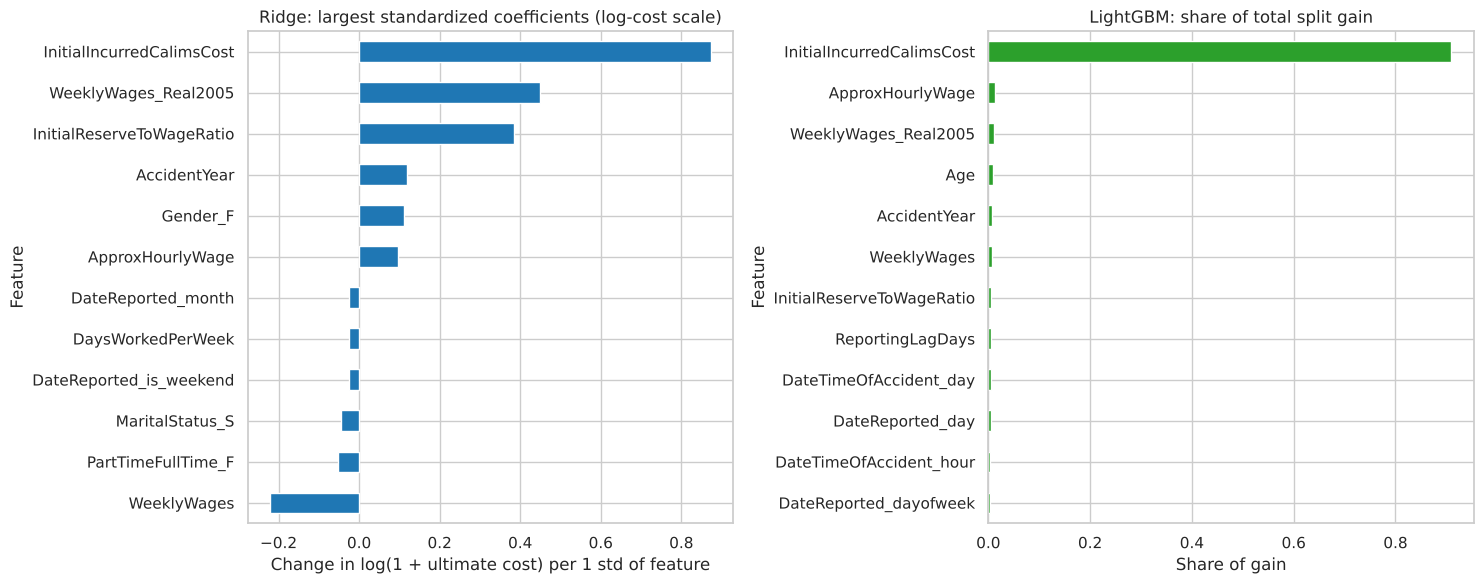

In [8]:
# Native view for the two most interpretable families
ridge = fitted_it1["Ridge"]
ridge_coef = pd.Series(
    ridge.named_steps["model"].regressor_.coef_,
    index=feature_names(ridge.named_steps["features"]),
).sort_values()
lgbm = fitted_it1["LightGBM"]
lgbm_gain = pd.Series(
    lgbm.named_steps["model"].regressor_.booster_.feature_importance("gain"),
    index=feature_names(lgbm.named_steps["features"]),
).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pd.concat([ridge_coef.head(6), ridge_coef.tail(6)]).plot.barh(ax=axes[0], color="#1f77b4")
axes[0].set(title="Ridge: largest standardized coefficients (log-cost scale)",
            xlabel="Change in log(1 + ultimate cost) per 1 std of feature", ylabel="Feature")
(lgbm_gain.head(12) / lgbm_gain.sum()).sort_values().plot.barh(ax=axes[1], color="#2ca02c")
axes[1].set(title="LightGBM: share of total split gain", xlabel="Share of gain", ylabel="Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_native_importance_iteration1.png", dpi=150, bbox_inches="tight")
plt.show()

**What the models rely on (iteration 1)**
* **`InitialIncurredCalimsCost` dominates every algorithm.** Shuffling it raises validation MAE by $3,500–7,000; the adjuster's reserve already encodes most of what is known at FNOL. The model's job is to *correct* that reserve, not replace it.
* **Notebook 02's engineered features carry real signal.** `InitialReserveToWageRatio` is the second most important column for Ridge, LinearSVR, KNN and RandomForest (≈ $1,200–1,700), and the CPI-adjusted `WeeklyWages_Real2005` is first among the wage features for both linear models (Ridge $1,843, LinearSVR $2,561). Wage replacement is a large share of workers' comp costs, and expressing it in constant dollars helps.
* For the boosted trees (LightGBM, XGBoost) importance is concentrated almost entirely on the reserve itself (≈ 90% of LightGBM's split gain). For linear models it is shared with the reserve-to-wage ratio and the real-dollar reserve, which carry overlapping information. This is why shuffling the reserve alone hurts them less.
* KNN relies on the initial reserve much less ($1,765) because its distance treats all scaled columns equally, which is exactly why it performs poorly. The MLP spreads importance over wages and working-pattern columns, a hint that its errors differ from the trees'.
* **`Gender` and `MaritalStatus` do not appear in the top 12 for any model**; in the native Ridge chart `Gender_F` and `MaritalStatus_S` have small coefficients. This motivates the feature-selection test in §3.6.

## 3.5 What types of errors do the models make?

We analyse the **out-of-fold** predictions from §3.3, so every training claim is scored by a model that did not see it. Four views:

1. **Error by claim size**: MAE inside each decile of the actual ultimate cost, for the adjuster and the models.
2. **Direction of errors**: how often each model under- vs over-predicts, and by how much.
3. **Error diversity**: correlation of the models' log-scale residuals. Low correlation means two models make *different* mistakes and are good ensemble partners (§3.8, Notebook 04).
4. **Worst misses**: the individual claims with the largest under-prediction, to see what a human would have needed to know.

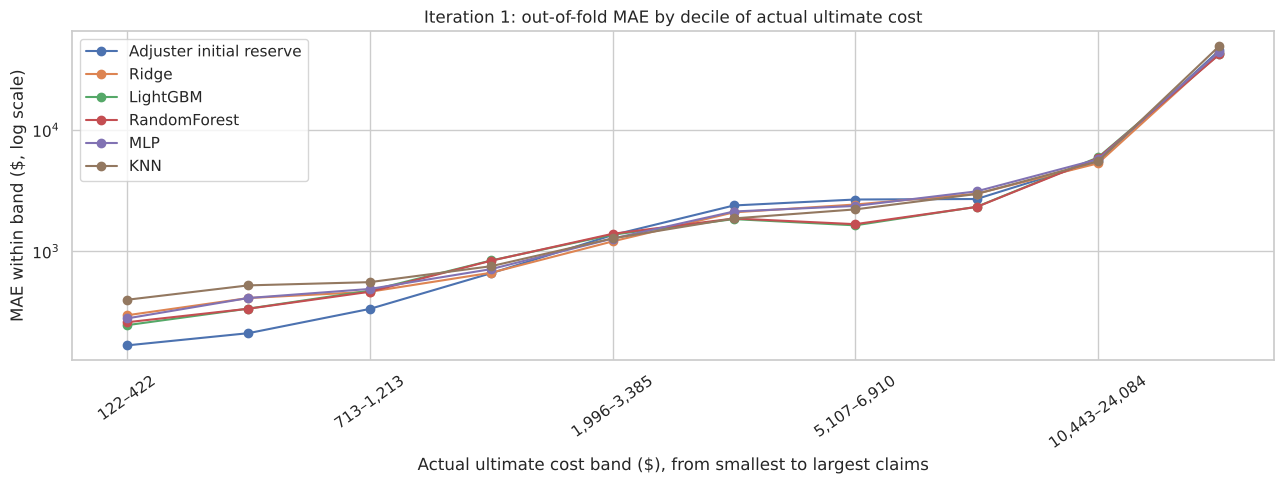

,Adjuster initial reserve,Ridge,LightGBM,RandomForest,MLP,KNN
122–422,168.00,298.00,247.00,261.00,280.00,399.00
422–713,212.00,413.00,338.00,337.00,413.00,525.00
"713–1,213",336.00,465.00,475.00,465.00,490.00,558.00
"1,213–1,995",661.00,667.00,843.00,839.00,715.00,756.00
"1,996–3,385","1,364.00","1,209.00","1,375.00","1,398.00","1,275.00","1,281.00"
"3,385–5,107","2,394.00","2,101.00","1,848.00","1,870.00","2,135.00","1,872.00"
"5,107–6,910","2,680.00","2,438.00","1,641.00","1,678.00","2,372.00","2,222.00"
"6,910–10,443","2,706.00","2,989.00","2,334.00","2,327.00","3,130.00","2,978.00"
"10,443–24,084","5,560.00","5,328.00","5,959.00","5,890.00","5,755.00","5,537.00"
"24,086–865,771","45,520.00","43,243.00","42,504.00","42,148.00","44,354.00","49,480.00"


In [9]:
IT1_MODELS = list(MODEL_ZOO)
oof_it1 = pd.DataFrame({m: OOF[f"{m} | it1"] for m in IT1_MODELS}, index=y_train.index)
oof_it1["Adjuster initial reserve"] = OOF["Adjuster initial reserve"]

deciles = pd.qcut(y_train, 10, labels=False)
band_labels = y_train.groupby(deciles).agg(["min", "max"]).apply(
    lambda r: f"{r['min']:,.0f}–{r['max']:,.0f}", axis=1)

show = ["Adjuster initial reserve", "Ridge", "LightGBM", "RandomForest", "MLP", "KNN"]
mae_by_band = pd.DataFrame({
    m: (y_train - oof_it1[m]).abs().groupby(deciles).mean() for m in show
})
mae_by_band.index = band_labels.values

fig, ax = plt.subplots(figsize=(13, 5))
mae_by_band.plot(ax=ax, marker="o", logy=True)
ax.set(title="Iteration 1: out-of-fold MAE by decile of actual ultimate cost",
       xlabel="Actual ultimate cost band ($), from smallest to largest claims",
       ylabel="MAE within band ($, log scale)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_error_by_cost_decile.png", dpi=150, bbox_inches="tight")
plt.show()
display(mae_by_band.round(0))

,share_under_predicted_%,mean_under_prediction_$,mean_over_prediction_$,share_of_abs_error_from_top_1%_claims_%
XGBoost,38.57,"4,303.92","1,513.30",29.36
LightGBM,38.42,"4,330.47","1,425.99",29.98
RandomForest,37.93,"4,398.63","1,322.73",30.68
DecisionTree,40.19,"4,403.98","1,510.23",29.35
MLP,40.92,"4,448.80","1,643.28",28.47
Ridge,40.00,"4,466.03","1,449.25",29.33
Adjuster initial reserve,54.00,"4,577.21","1,583.19",27.41
LinearSVR,50.22,"4,938.51",806.04,31.27
KNN,49.98,"5,859.60",701.38,29.33


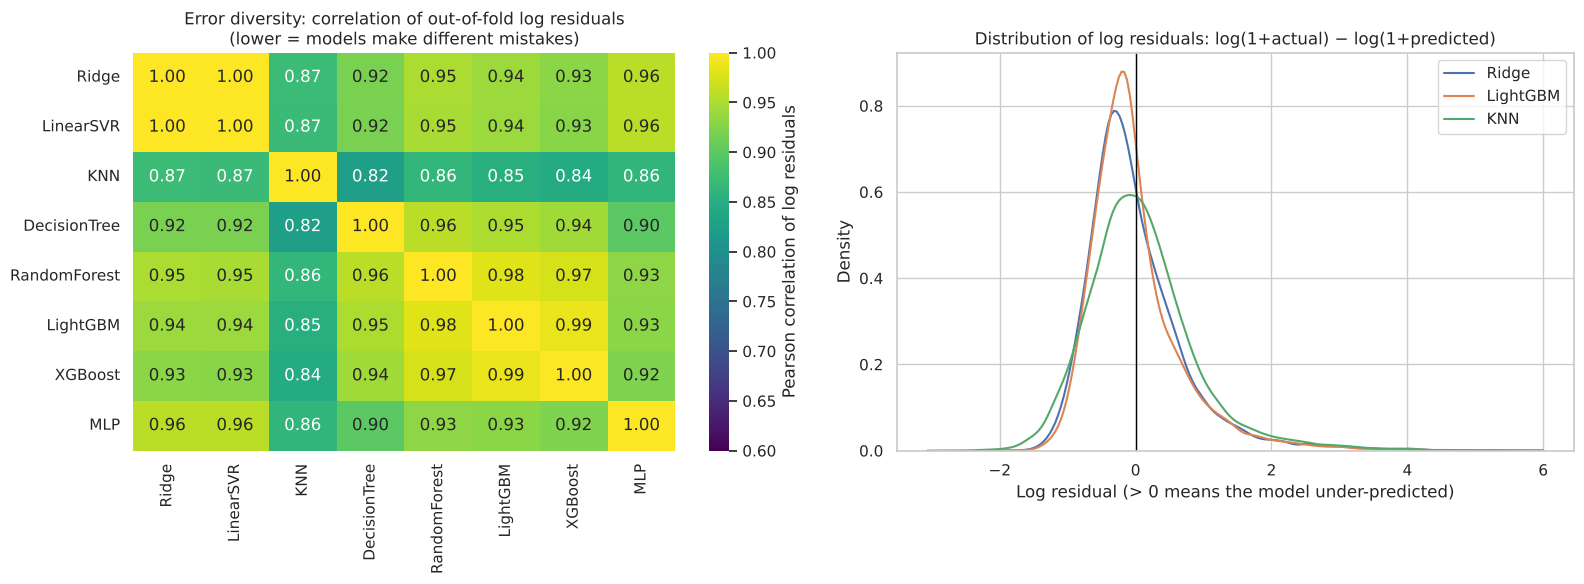

In [10]:
direction = pd.DataFrame({
    "share_under_predicted_%": {m: 100 * (y_train > oof_it1[m]).mean() for m in oof_it1},
    "mean_under_prediction_$": {m: (y_train - oof_it1[m]).clip(lower=0).mean() for m in oof_it1},
    "mean_over_prediction_$": {m: (oof_it1[m] - y_train).clip(lower=0).mean() for m in oof_it1},
    "share_of_abs_error_from_top_1%_claims_%": {
        m: 100 * (y_train - oof_it1[m]).abs()[y_train >= y_train.quantile(0.99)].sum()
           / (y_train - oof_it1[m]).abs().sum() for m in oof_it1},
}).sort_values("mean_under_prediction_$")
display(direction)

log_resid = np.log1p(y_train.values)[:, None] - np.log1p(oof_it1[IT1_MODELS].clip(lower=0).values)
resid_corr = pd.DataFrame(log_resid, columns=IT1_MODELS).corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(resid_corr, annot=True, fmt=".2f", cmap="viridis", vmin=0.6, vmax=1, ax=axes[0],
            cbar_kws={"label": "Pearson correlation of log residuals"})
axes[0].set_title("Error diversity: correlation of out-of-fold log residuals\n(lower = models make different mistakes)")
for m in ["Ridge", "LightGBM", "KNN"]:
    sns.kdeplot(pd.DataFrame(log_resid, columns=IT1_MODELS)[m], ax=axes[1], label=m, clip=(-4, 6))
axes[1].axvline(0, color="black", lw=1)
axes[1].set(title="Distribution of log residuals: log(1+actual) − log(1+predicted)",
            xlabel="Log residual (> 0 means the model under-predicted)", ylabel="Density")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_error_diversity.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
worst = train_df.assign(
    predicted_LightGBM=oof_it1["LightGBM"].values,
    under_prediction=y_train.values - oof_it1["LightGBM"].values,
).nlargest(12, "under_prediction")
display(worst[[TEXT_COL, "Age", "WeeklyWages", INITIAL_COL, "predicted_LightGBM", TARGET_COL, "under_prediction"]])

# Do the costliest claims use different words? Compare word frequency in the top 5% vs the rest.
is_large = y_train >= y_train.quantile(0.95)
words = X_train[TEXT_COL].str.split().explode()
large_share = words[is_large.reindex(words.index).values].value_counts(normalize=True)
rest_share = words[~is_large.reindex(words.index).values].value_counts(normalize=True)
lift = (large_share / rest_share).dropna()
lift = lift[large_share.reindex(lift.index) > 0.003].sort_values(ascending=False)
print("Words most over-represented in the costliest 5% of claims (lift = frequency ratio):")
display(lift.head(15).round(2).to_frame("lift_vs_other_claims"))

,ClaimDescription,Age,WeeklyWages,InitialIncurredCalimsCost,predicted_LightGBM,UltimateIncurredClaimCost,under_prediction
16105,WHILST MASSAGING FELT PAIN SOFT TISSUE INJURY ...,37,200.00,7500,"5,451.82","865,770.65","860,318.83"
20250,LIFTING BOX FROM TOOL BOX HERNIA,46,"1,183.00",250000,"115,805.28","713,784.06","597,978.78"
16439,SCRAPER SLIPPED AND HIT HEAD HYPERFLEXION INJU...,21,300.12,5000,"7,095.39","536,763.47","529,668.09"
1229,CAUGHT BETWEEN DOOR FRAME GRAZE HEAD,55,"1,522.70",119686,"76,837.93","558,408.96","481,571.03"
24221,PULLING ON WRENCH GAVE WAY FELL BRUISED RIGHT ...,31,927.40,10000,"10,234.14","489,888.11","479,653.97"
19362,SLIPPED FELL ON HEAD CUT HEAD MILD CONCUSSION,35,425.40,19000,"18,499.99","475,911.57","457,411.58"
23782,LIFTING CRATES INJURED BACK,53,727.45,3500,"7,627.65","457,718.76","450,091.10"
562,PULLED MUSCLE LOWER BACK STRAIN,22,434.80,28000,"21,742.82","457,049.86","435,307.04"
13175,LIFTING SCAFFOLDING SHOULDER,30,570.00,1500,"2,711.07","419,913.09","417,202.03"
20784,CAUGHT BETWEEN PALLETS SOFT TISSUE INJURY LEFT...,52,366.95,48545,"48,671.12","445,814.45","397,143.33"


Words most over-represented in the costliest 5% of claims (lift = frequency ratio):


,lift_vs_other_claims
ClaimDescription,
STRESS,6.39
WORK,3.42
REPETITIVE,2.66
MOVING,2.49
FALL,2.21
SHOULDER,2.20
ACCIDENT,2.07
VEHICLE,2.07
PAIN,2.05


**Types of errors**
1. **Errors depend strongly on claim size.** On the smallest claims (under ~$2,000) the models are *worse* than the adjuster: they pull small reserves up toward the typical development. On middle-sized claims ($3,400–$10,400) they are clearly better (e.g. LightGBM $1,641 vs adjuster $2,680 in the $5,100–$6,900 band). On the top decile (> $24,000) everyone is poor (MAE ≈ $42,000–45,000): these are the claims that develop unexpectedly.
2. **The models under-predict less often but by more.** The adjuster under-reserves 54% of claims; the tree models only ~38%. When the models do under-predict, it is mostly on rare catastrophic claims: the top 1% of claims cause 28–31% of all absolute error for every method.
3. **Error diversity.** Log residuals of LightGBM, XGBoost and RandomForest are highly correlated (≈ 0.95–0.98), so they make the same mistakes. Ridge/LinearSVR (≈ 0.85–0.87 with the trees) and the MLP (≈ 0.88) err differently, which makes them useful ensemble partners.
4. **Worst misses.** The 12 largest under-predictions all have final costs above $360,000, and several start from a *modest* reserve (e.g. "WHILST MASSAGING FELT PAIN SOFT TISSUE INJURY…": reserve $7,500, final $865,771; "LIFTING SCAFFOLDING SHOULDER": reserve $1,500, final $419,913). Nothing in the structured fields distinguishes them from thousands of similar soft-tissue, back and shoulder claims.

**What data would a human have used to avoid these errors?** An experienced adjuster would look at (a) the **injury description**: words like *stress*, *repetitive*, *moving*, *fall*, *shoulder*, *vehicle* or *back* are 1.6× to 6.4× more frequent in the costliest 5% of claims than in the rest (table above), and this text is in our data but unused so far; (b) **medical information** (diagnosis codes, surgery, imaging), (c) **time off work / return-to-work status** and (d) **litigation or lawyer involvement**. Items (b)–(d) are not in the dataset and are listed as extra data in the limitations. Item (a) is available at FNOL, so we add it in iteration 2.

## 3.6 Iteration 2: quick round of feature engineering and feature selection

Based on the error analysis we make two changes and re-run every model with the same folds:

**Feature engineering: add the claim description as text features.** `ClaimDescription` has about 20,600 distinct phrases (EDA), so one-hot encoding whole phrases is useless. We use `TfidfVectorizer` (unigrams + bigrams, words appearing in at least 3 claims, top 2,000 terms, sub-linear term frequency). Linear models receive the sparse TF-IDF matrix directly; other families receive 50 `TruncatedSVD` components ("latent topics") because trees, KNN and neural nets handle a few dense columns far better than 2,000 sparse ones. Both live inside the pipeline, so the vocabulary is learned on training folds only.

**Feature selection: drop `Gender` and `MaritalStatus`.** Iteration 1 permutation importance shows these personal attributes contribute almost nothing, and using them to set reserves raises fairness and privacy concerns (EDA column notes). We keep them out if removing them does not hurt accuracy, which the ablation below tests.

In [12]:
for name, (family, _) in MODEL_ZOO.items():
    t0 = time.time()
    folds_df, OOF[f"{name} | it2"] = cv_evaluate(make_pipeline(name, X_train, use_text=True))
    summary_rows.append(summarise(name, folds_df, family, "2 - + text"))
    print(f"{name:<13} MAE {folds_df['MAE'].mean():>8,.0f} ± {folds_df['MAE'].std():>5,.0f}   ({time.time() - t0:,.0f}s)")

# Feature selection ablation: the same LightGBM with the two personal attributes removed
X_train_fs = X_train.drop(columns=SENSITIVE_COLS)
folds_df, OOF["LightGBM | it2 no-sensitive"] = cv_evaluate(make_pipeline("LightGBM", X_train_fs, use_text=True), X_train_fs)
summary_rows.append(summarise("LightGBM (no Gender/MaritalStatus)", folds_df, "Boosting", "2 - + text"))
print(f"LightGBM without Gender/MaritalStatus: MAE {folds_df['MAE'].mean():,.0f} ± {folds_df['MAE'].std():,.0f}")

Ridge         MAE    5,909 ±   418   (3s)


LinearSVR     MAE    5,570 ±   422   (7s)


KNN           MAE    6,541 ±   453   (5s)


DecisionTree  MAE    5,880 ±   456   (6s)


RandomForest  MAE    5,517 ±   419   (78s)


LightGBM      MAE    5,516 ±   401   (17s)


XGBoost       MAE    5,579 ±   396   (28s)


MLP           MAE    5,783 ±   308   (16s)


LightGBM without Gender/MaritalStatus: MAE 5,504 ± 412


,model,family,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MedianAE_mean,MeanBias(actual-pred)_mean,MAE_vs_adjuster_%,fit_seconds
0,LightGBM (no Gender/MaritalStatus),Boosting,"5,503.80",411.63,"22,807.64","3,046.91",642.22,"2,684.95",-10.67,5.69
1,LightGBM,Boosting,"5,516.34",400.59,"22,836.34","3,013.32",654.07,"2,693.26",-10.46,5.74
2,RandomForest,Bagging,"5,517.07",418.72,"23,015.63","3,134.64",701.97,"2,964.53",-10.45,25.72
3,LinearSVR,SVM,"5,570.42",422.48,"23,469.49","3,035.34",554.95,"4,003.57",-9.59,2.14
4,XGBoost,Boosting,"5,578.58",396.14,"22,841.08","2,990.28",650.70,"2,560.82",-9.45,9.47
5,MLP,Neural net,"5,782.61",308.18,"23,090.60","2,929.11",719.65,"2,600.18",-6.14,5.35
6,DecisionTree,Single tree,"5,879.57",456.45,"23,099.74","3,043.74",813.02,"2,708.92",-4.57,1.77
7,Ridge,Linear,"5,908.77",417.72,"23,105.85","3,033.30",676.91,"2,725.05",-4.09,0.86
8,Adjuster initial reserve,Baseline,"6,161.06",315.95,"24,581.05","2,181.16","1,036.13","2,995.12",0.00,0.00
9,Initial x dev. factor,Baseline,"6,308.77",301.78,"24,808.96","2,122.95","1,068.33","2,489.43",2.40,0.00


iteration,1 - structured,2 - + text,MAE change from text ($),MAE change (%)
model,,,,
LightGBM,"5,757.35","5,516.34",-241.01,-4.19
RandomForest,"5,722.23","5,517.07",-205.16,-3.59
LinearSVR,"5,745.43","5,570.42",-175.01,-3.05
XGBoost,"5,818.04","5,578.58",-239.45,-4.12
MLP,"6,092.72","5,782.61",-310.11,-5.09
DecisionTree,"5,915.14","5,879.57",-35.57,-0.60
Ridge,"5,916.11","5,908.77",-7.34,-0.12
KNN,"6,561.91","6,541.39",-20.53,-0.31


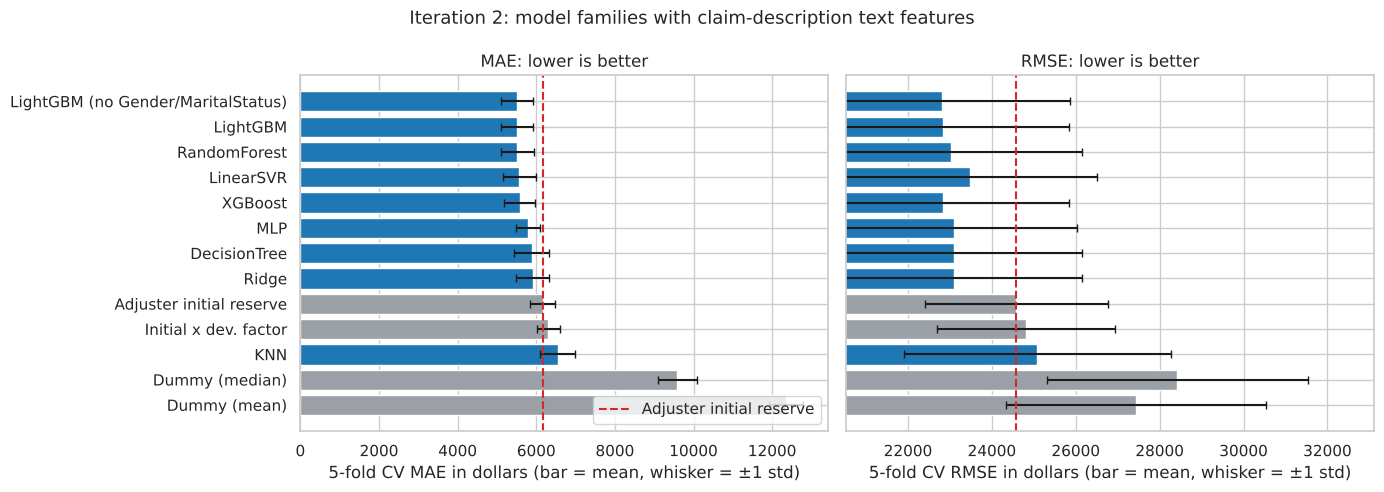

In [13]:
it2_table = results_table("2 - + text")
display(it2_table)

compare = (pd.DataFrame(summary_rows)
           .query("iteration in ['1 - structured', '2 - + text'] and model in @IT1_MODELS")
           .pivot(index="model", columns="iteration", values="MAE_mean"))
compare["MAE change from text ($)"] = compare["2 - + text"] - compare["1 - structured"]
compare["MAE change (%)"] = 100 * compare["MAE change from text ($)"] / compare["1 - structured"]
display(compare.sort_values("2 - + text"))

plot_cv(it2_table, "Iteration 2: model families with claim-description text features", "03_cv_iteration2_text.png")

**Iteration 2 results**
* **Adding the claim-description text improved every strong model**: MLP −$310 (−5.1%), LightGBM −$241, XGBoost −$239, RandomForest −$205, LinearSVR −$175. LightGBM ($5,516) and RandomForest ($5,517) now beat the adjuster by **~10.5%** on MAE, and their median absolute error drops to ~$650–700 vs $1,036 for the adjuster.
* Ridge barely benefited (−$7): with 2,000 sparse word columns and the default `alpha=1.0` it is under-regularised. This is a tuning issue, not evidence that text is useless (LinearSVR, the other linear model, gained $175).
* **Feature selection: removing `Gender` and `MaritalStatus` slightly *improved* LightGBM** (MAE 5,516 → 5,504), well inside one fold standard deviation ($412). We therefore drop both for all shortlisted models: no accuracy cost, and the reserve recommendation no longer depends on a worker's gender or marital status.
* The RMSE panel shows overlapping error bars driven by a handful of very large claims; RMSE barely separates the models.

## 3.7 Iteration 3: which loss / target transform fits the business metric?

The log target in §3.3 was a reasonable default, but it is a modelling *choice*: a model trained on squared error in log space predicts something close to the conditional **median**, not the mean, so on heavy-tailed costs it systematically under-predicts the dollar total. We test five alternatives on the best family so far (LightGBM, with text, without sensitive columns):

| Variant | Loss | What it estimates |
|---|---|---|
| log + L2 | squared error on `log1p(cost)` | ≈ conditional median (geometric mean) |
| raw + L2 | squared error in dollars | conditional mean, very sensitive to outliers |
| raw + L1 | absolute error in dollars | conditional median, directly optimises MAE |
| raw + Huber | squared near zero, absolute in the tails | compromise |
| raw + Tweedie | Tweedie deviance (actuarial standard for skewed positive costs) | conditional mean, but less outlier-driven than L2 |

In [14]:
def lgbm_variant(objective, log_target, **params):
    base = lgb.LGBMRegressor(objective=objective, n_estimators=400, learning_rate=0.05, n_jobs=1,
                             random_state=RANDOM_STATE, verbose=-1, **params)
    reg = TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1) if log_target else base
    return Pipeline([("features", build_feature_pipeline(X_train_fs, use_text=True, text_svd_components=50)),
                     ("model", reg)])


variants = {
    "log + L2": lgbm_variant("regression", True),
    "raw + L2": lgbm_variant("regression", False),
    "raw + L1": lgbm_variant("regression_l1", False),
    "raw + Huber": lgbm_variant("huber", False, alpha=5000.0),
    "raw + Tweedie": lgbm_variant("tweedie", False, tweedie_variance_power=1.5),
}
loss_rows = []
for vname, pipe in variants.items():
    folds_df, OOF[f"LightGBM {vname}"] = cv_evaluate(pipe, X_train_fs)
    row = summarise(f"LightGBM {vname}", folds_df, "Boosting", "3 - loss")
    row["total_predicted_/_total_actual"] = OOF[f"LightGBM {vname}"].sum() / y_train.sum()
    loss_rows.append(row)
    summary_rows.append(row)

loss_table = pd.DataFrame(loss_rows).set_index("model")[
    ["MAE_mean", "MAE_std", "RMSE_mean", "MedianAE_mean", "MeanBias(actual-pred)_mean", "total_predicted_/_total_actual"]]
adj_ratio = X_train[INITIAL_COL].sum() / y_train.sum()
print(f"For reference, the adjuster's total initial reserve covers {adj_ratio:.1%} of the total ultimate cost.")
display(loss_table)

For reference, the adjuster's total initial reserve covers 72.2% of the total ultimate cost.


,MAE_mean,MAE_std,RMSE_mean,MedianAE_mean,MeanBias(actual-pred)_mean,total_predicted_/_total_actual
model,,,,,,
LightGBM log + L2,"5,503.80",411.63,"22,807.64",642.22,"2,684.95",0.75
LightGBM raw + L2,"7,803.91",289.42,"23,428.76","2,211.52",-190.56,1.02
LightGBM raw + L1,"5,189.23",431.15,"23,451.00",474.85,"4,071.95",0.62
LightGBM raw + Huber,"5,320.71",420.81,"23,291.97",676.02,"3,528.61",0.67
LightGBM raw + Tweedie,"6,181.13",390.46,"22,798.60","1,032.88","1,566.88",0.85


**The loss function is a business decision, not only a technical one**

| Variant | MAE | Total predicted / total actual |
|---|---|---|
| raw + L1 | **$5,189** (best) | 62% |
| raw + Huber | $5,321 | 67% |
| log + L2 (current) | $5,504 | 75% |
| raw + Tweedie | $6,181 (worse than adjuster) | 85% |
| raw + L2 | $7,804 (worse than adjuster) | **102%** |
| *Adjuster* | *$6,161* | *72%* |

* Losses that target the **median** (L1, Huber, log + L2) give the best per-claim accuracy (MAE) but predict only 62–75% of the total dollars, because a few huge claims carry much of the total. Losses that target the **mean** (raw L2, and to a lesser extent Tweedie) get the total closer to right but are worse than the adjuster on the typical claim.
* Our use case is **claim-level triage** ("which reserves look wrong?"), and the README chose MAE as the primary metric, so we keep the median-type losses. Aggregate reserve adequacy for the whole portfolio is handled separately by actuarial methods (e.g. chain-ladder on development triangles), and we flag it as a limitation.
* Raw + L1 and raw + Huber beat log + L2 on MAE, so **the loss/target transform becomes a hyperparameter in Notebook 04** for LightGBM rather than a fixed choice.

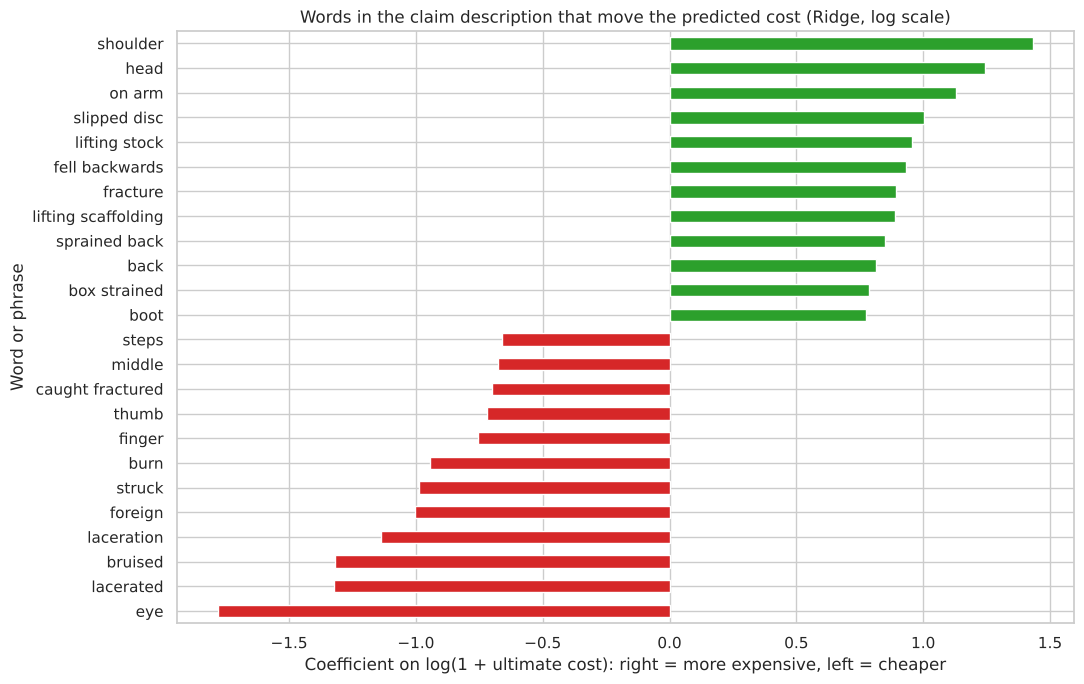

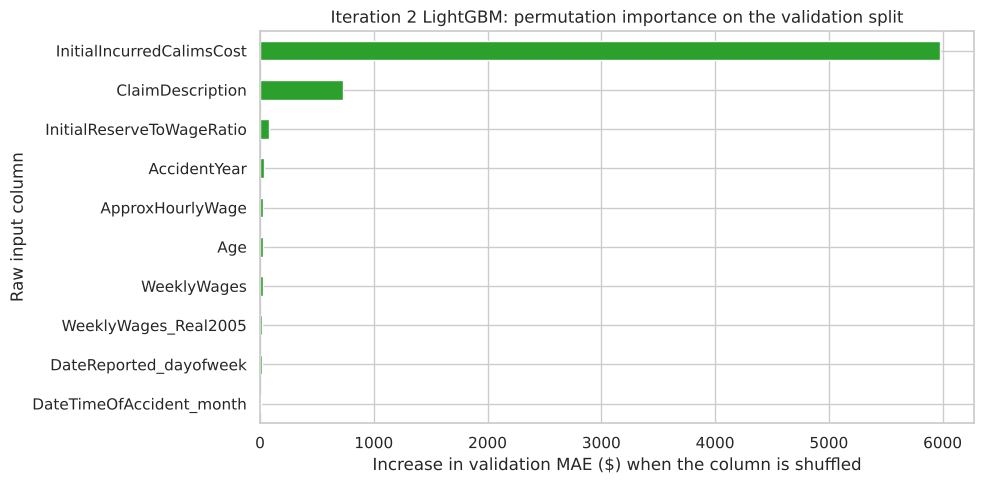

In [15]:
# What does the text actually contribute? Ridge on sparse TF-IDF gives one weight per word or phrase.
ridge_text = make_pipeline("Ridge", X_train_fs, use_text=True).fit(X_train_fs, y_train)
coefs = pd.Series(ridge_text.named_steps["model"].regressor_.coef_,
                  index=feature_names(ridge_text.named_steps["features"]))
word_coefs = coefs[coefs.index.str.startswith("word:")].sort_values()
word_coefs.index = word_coefs.index.str.replace("word:", "", regex=False)

fig, ax = plt.subplots(figsize=(11, 7))
pd.concat([word_coefs.head(12), word_coefs.tail(12)]).plot.barh(
    ax=ax, color=["#d62728"] * 12 + ["#2ca02c"] * 12)
ax.set(title="Words in the claim description that move the predicted cost (Ridge, log scale)",
       xlabel="Coefficient on log(1 + ultimate cost): right = more expensive, left = cheaper",
       ylabel="Word or phrase")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_text_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

# Permutation importance for the iteration-2 LightGBM (now including the text column)
lgbm_it2 = make_pipeline("LightGBM", X_train_fs, use_text=True).fit(X_train_fs, y_train)
X_val_fs = X_val.drop(columns=SENSITIVE_COLS)
r = permutation_importance(lgbm_it2, X_val_fs, y_val, scoring=mae_scorer, n_repeats=5,
                           random_state=RANDOM_STATE, n_jobs=N_JOBS)
perm_it2 = pd.Series(r.importances_mean, index=X_val_fs.columns).sort_values(ascending=False)
ax = perm_it2.head(10).sort_values().plot.barh(figsize=(10, 5), color="#2ca02c")
ax.set(title="Iteration 2 LightGBM: permutation importance on the validation split",
       xlabel="Increase in validation MAE ($) when the column is shuffled", ylabel="Raw input column")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_permutation_importance_iteration2.png", dpi=150, bbox_inches="tight")
plt.show()

**What the text adds**
* After the initial reserve, **`ClaimDescription` is now the second most important input** for LightGBM (shuffling it costs about $720 of validation MAE), far ahead of every other column (`InitialReserveToWageRatio` is next at under $100).
* The Ridge word weights read like adjuster intuition. Words and phrases pushing the cost **up**: *shoulder*, *head*, *slipped disc*, *fell backwards*, *fracture*, *sprained back*, *lifting stock/scaffolding*. Words pushing it **down**: *eye* and *foreign* (foreign body in eye), *lacerated/laceration*, *bruised*, *burn*, *struck*, *finger*, *thumb*. Minor, well-defined injuries resolve cheaply; musculoskeletal, back and head injuries develop.
* This gives the presentation a memorable takeaway: **"the adjuster's reserve sets the level; the words in the claim description tell you which way it will drift."**

## 3.8 Shortlist for fine-tuning

The checklist asks for the top three to five models, **preferring models that make different types of errors**. Below we combine iteration-2 CV performance with the error-diversity of their out-of-fold residuals.

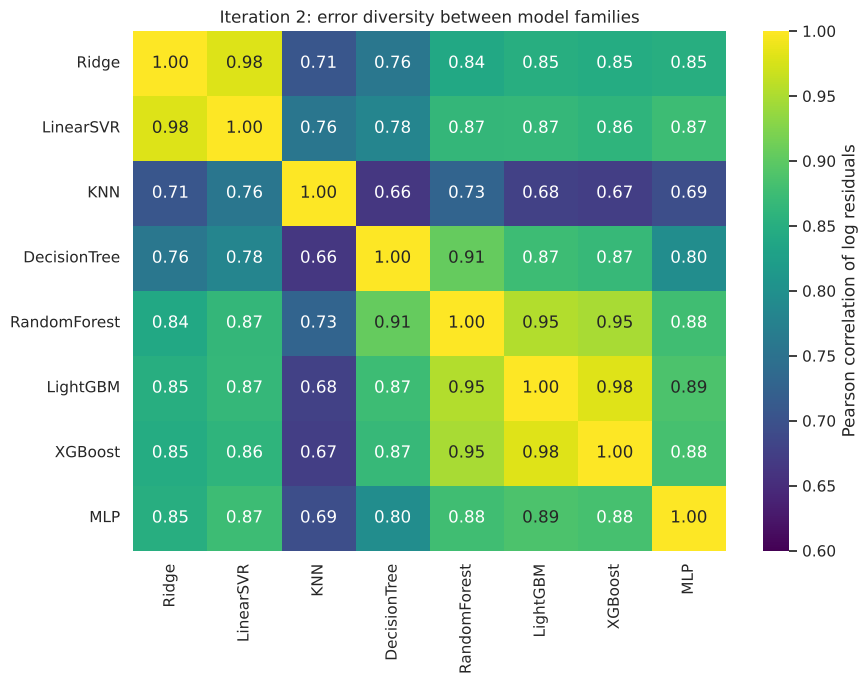

Average of LightGBM + XGBoost                            OOF MAE 5,529
Average of LightGBM + RandomForest                       OOF MAE 5,474
Average of LightGBM + LinearSVR                          OOF MAE 5,321
Average of LightGBM + RandomForest + LinearSVR + MLP     OOF MAE 5,366


In [16]:
IT2_MODELS = [m for m in IT1_MODELS]
log_resid2 = pd.DataFrame(
    np.log1p(y_train.values)[:, None] - np.log1p(np.column_stack([OOF[f"{m} | it2"] for m in IT2_MODELS]).clip(min=0)),
    columns=IT2_MODELS)
resid_corr2 = log_resid2.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(resid_corr2, annot=True, fmt=".2f", cmap="viridis", vmin=0.6, vmax=1,
            cbar_kws={"label": "Pearson correlation of log residuals"})
plt.title("Iteration 2: error diversity between model families")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_error_diversity_iteration2.png", dpi=150, bbox_inches="tight")
plt.show()

# Quick check of how much a simple average of diverse models could gain (motivation for Notebook 04)
def blend_mae(models):
    pred = np.mean([OOF[f"{m} | it2"] for m in models], axis=0)
    return regression_report(y_train, pred)["MAE"]

for combo in [["LightGBM", "XGBoost"], ["LightGBM", "RandomForest"], ["LightGBM", "LinearSVR"],
              ["LightGBM", "RandomForest", "LinearSVR", "MLP"]]:
    print(f"Average of {' + '.join(combo):<45} OOF MAE {blend_mae(combo):,.0f}")

**Shortlisted models for Notebook 04**

| Model | Iteration-2 CV MAE | Why it is shortlisted |
|---|---|---|
| **LightGBM** | $5,516 ± 401 | Joint best accuracy, fast (~6 s per fit), and its loss function is tunable (§3.7). |
| **RandomForest** | $5,517 ± 419 | Joint best accuracy; bagging rather than boosting, fewer over-predictions than the boosted trees. Averaging it with LightGBM lowers OOF MAE to $5,474. |
| **LinearSVR** | $5,570 ± 422 | Different family and the most different errors among accurate models (log-residual correlation 0.87 with LightGBM). LightGBM + LinearSVR averaged gives the best pair: **$5,321**. |
| **MLP** | $5,783 ± 308 | Only neural-network family; correlation 0.89 with LightGBM; leans on wage and working-pattern features the trees ignore; the lowest fold-to-fold variability (±$308) and the most to gain from tuning. |

**Not shortlisted:** XGBoost (accurate, but its errors are 0.98-correlated with LightGBM, so it adds little diversity), DecisionTree (dominated by RandomForest), Ridge (dominated by LinearSVR in the same family), KNN (worse than the adjuster).

All four use Notebook 02's engineered features plus the claim-description text, without `Gender`/`MaritalStatus`.

In [17]:
# Persist results so Notebook 04, the README and the slides use the same numbers
all_results = pd.DataFrame(summary_rows)
all_results.to_csv(TABLES_DIR / "03_cv_results_all_iterations.csv", index=False)

SHORTLIST = ["LightGBM", "RandomForest", "LinearSVR", "MLP"]
with open(TABLES_DIR / "03_shortlist.json", "w") as f:
    json.dump({"shortlist": SHORTLIST, "drop_columns": SENSITIVE_COLS, "use_text": True,
               "target_transform": "log1p", "cv": "GroupKFold(5, shuffle=True, random_state=42) on ClaimNumber"}, f, indent=2)
print("Saved:", TABLES_DIR / "03_cv_results_all_iterations.csv")
print("Shortlist:", SHORTLIST)

Saved: /home/claude/insy674-group-project/reports/tables/03_cv_results_all_iterations.csv
Shortlist: ['LightGBM', 'RandomForest', 'LinearSVR', 'MLP']


## 3.9 Summary of findings (for the README and slides)

* **Baseline to beat:** the adjuster's initial reserve, MAE **$6,161**; it under-reserves 54% of claims.
* **Seven of eight model families beat it** using only structured fields (Notebook 02's engineered features); the best (RandomForest, LinearSVR, LightGBM) by ~7%.
* **Notebook 02's engineered features matter**: the reserve-to-wage ratio and CPI-adjusted wages are the second tier of importance for linear and forest models.
* **The claim description is the most valuable addition**: TF-IDF text features cut MAE by up to $310 and bring the best models to **~10.5% below the adjuster** ($5,516–$5,517), with typical-claim error (median AE) down from $1,036 to ~$650.
* **Gender and marital status can be dropped at no cost** (MAE actually 5,516 → 5,504).
* **Error profile:** models beat the adjuster on mid-sized claims, are slightly worse on very small ones, and, like the adjuster, cannot foresee the rare catastrophic claims (the top 1% of claims cause 28–31% of all error).
* **Loss choice is a business trade-off**: median-type losses minimise per-claim error but under-predict total dollars; mean-type losses get totals closer to right but lose to the adjuster per claim.
* **Diversity is real and useful**: an average of LightGBM and LinearSVR (OOF MAE $5,321) beats either model alone, which motivates the ensembles in Notebook 04.
* **Shortlist:** LightGBM, RandomForest, LinearSVR, MLP.